In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
destinations = pd.read_csv(
    "../data/processed/cleaned_destinations.csv"
)

print("Dataset Shape:", destinations.shape)

print(destinations[
    ["name_en", "country_en", "latitude", "longitude"]
].head())

Dataset Shape: (33264, 33)
                name_en            country_en   latitude  longitude
0          Capital Gate  United Arab Emirates  24.418636  54.434692
1  Guggenheim Abu Dhabi  United Arab Emirates  24.539514  54.398958
2  Disneyland Abu Dhabi  United Arab Emirates  24.485853  54.602978
3         Etihad Towers  United Arab Emirates  24.459322  54.321297
4             Sky Tower  United Arab Emirates  24.495948  54.407514


In [4]:
X = destinations[["latitude", "longitude"]]

print(X.head())

    latitude  longitude
0  24.418636  54.434692
1  24.539514  54.398958
2  24.485853  54.602978
3  24.459322  54.321297
4  24.495948  54.407514


In [5]:
X = destinations[["latitude", "longitude"]]

print(X.head())

    latitude  longitude
0  24.418636  54.434692
1  24.539514  54.398958
2  24.485853  54.602978
3  24.459322  54.321297
4  24.495948  54.407514


Scale geographical data

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Data Shape:", X_scaled.shape)
print(X_scaled[:5])

Scaled Data Shape: (33264, 2)
[[-0.70233757  0.84645615]
 [-0.69602039  0.8458504 ]
 [-0.69882476  0.84930888]
 [-0.70021129  0.84453391]
 [-0.69829718  0.84599544]]


Apply K-Means clustering

In [7]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

destinations["cluster"] = kmeans.fit_predict(X_scaled)

print("Clustering Completed!")

print(destinations["cluster"].value_counts().sort_index())

Clustering Completed!
cluster
0    21236
1     1620
2     4587
3     5468
4      353
Name: count, dtype: int64


Visualise destination clusters

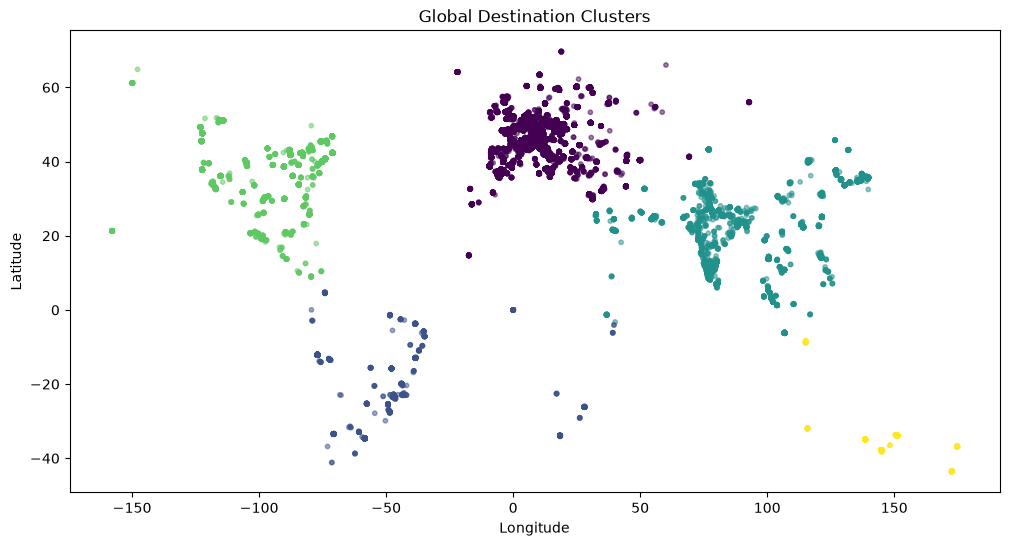

In [8]:
plt.figure(figsize=(12, 6))

plt.scatter(
    destinations["longitude"],
    destinations["latitude"],
    c=destinations["cluster"],
    cmap="viridis",
    s=10,
    alpha=0.5
)

plt.title("Global Destination Clusters")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

In [9]:
import joblib
import os

In [10]:
os.makedirs("../models", exist_ok=True)

joblib.dump(kmeans, "../models/clustering_model.pkl")

joblib.dump(scaler, "../models/destination_scaler.pkl")

destinations.to_csv(
    "../data/processed/clustered_destinations.csv",
    index=False
)

print("Clustering Model Saved Successfully!")

Clustering Model Saved Successfully!


Test the saved clustering model

In [11]:
# Load saved model and scaler
loaded_kmeans = joblib.load("../models/clustering_model.pkl")
loaded_scaler = joblib.load("../models/destination_scaler.pkl")

# Example location: Paris
new_location = pd.DataFrame({
    "latitude": [48.8566],
    "longitude": [2.3522]
})

# Scale location
new_location_scaled = loaded_scaler.transform(new_location)

# Predict cluster
prediction = loaded_kmeans.predict(new_location_scaled)

print("Location: Paris")
print("Predicted Cluster:", prediction[0])

Location: Paris
Predicted Cluster: 0


Destination Recommendation System

In [12]:
# Select required columns
recommendation_data = destinations[
    ["name_en", "country_en", "city_en",
     "category", "latitude", "longitude"]
].copy()

# Remove missing values
recommendation_data = recommendation_data.dropna(
    subset=["name_en", "latitude", "longitude", "category"]
)

recommendation_data = recommendation_data.reset_index(drop=True)

print("Recommendation Dataset:", recommendation_data.shape)

display(recommendation_data.head())

Recommendation Dataset: (33264, 6)


,name_en,country_en,city_en,category,latitude,longitude
0,Capital Gate,United Arab Emirates,Abu Dhabi,building,24.418636,54.434692
1,Guggenheim Abu Dhabi,United Arab Emirates,Abu Dhabi,attraction,24.539514,54.398958
2,Disneyland Abu Dhabi,United Arab Emirates,Abu Dhabi,amusement-park,24.485853,54.602978
3,Etihad Towers,United Arab Emirates,Abu Dhabi,tower,24.459322,54.321297
4,Sky Tower,United Arab Emirates,Abu Dhabi,building,24.495948,54.407514


Create the recommendation function

In [13]:
import numpy as np

def recommend_places(place_name, top_n=5):

    # Find selected destination
    selected = recommendation_data[
        recommendation_data["name_en"].str.lower() == place_name.lower()
    ]

    if selected.empty:
        print("Destination not found!")
        return

    selected = selected.iloc[0]

    # Calculate geographical distance
    lat1 = np.radians(selected["latitude"])
    lon1 = np.radians(selected["longitude"])

    lat2 = np.radians(recommendation_data["latitude"])
    lon2 = np.radians(recommendation_data["longitude"])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    distance = 6371 * 2 * np.arcsin(np.sqrt(a))

    # Add distance column
    results = recommendation_data.copy()
    results["distance_km"] = distance

    # Exclude selected destination
    results = results[results["name_en"] != place_name]

    # Recommend nearest destinations
    results = results.sort_values("distance_km").head(top_n)

    return results[
        ["name_en", "country_en", "category", "distance_km"]
    ].round({"distance_km": 2})

Create the recommendation function

In [14]:
import numpy as np

def recommend_places(place_name, top_n=5):

    # Find selected destination
    selected = recommendation_data[
        recommendation_data["name_en"].str.lower() == place_name.lower()
    ]

    if selected.empty:
        print("Destination not found!")
        return

    selected = selected.iloc[0]

    # Calculate geographical distance
    lat1 = np.radians(selected["latitude"])
    lon1 = np.radians(selected["longitude"])

    lat2 = np.radians(recommendation_data["latitude"])
    lon2 = np.radians(recommendation_data["longitude"])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    distance = 6371 * 2 * np.arcsin(np.sqrt(a))

    # Add distance column
    results = recommendation_data.copy()
    results["distance_km"] = distance

    # Exclude selected destination
    results = results[results["name_en"] != place_name]

    # Recommend nearest destinations
    results = results.sort_values("distance_km").head(top_n)

    return results[
        ["name_en", "country_en", "category", "distance_km"]
    ].round({"distance_km": 2})

Test the recommendation system

In [15]:
recommend_places("Paris", top_n=5)

,name_en,country_en,category,distance_km
2768,Bell Telephone Memorial,Canada,monument,11.13
2766,Bell Homestead National Historic Site,Canada,building,13.35
2872,Homer Watson House,Canada,building,22.50
2873,Waterloo Pioneer Memorial Tower,Canada,tower,23.07
2866,Westfield Heritage Centre,Canada,museum,24.05


In [22]:
import ast

with open("../src/recommendation.py", "r") as file:
    code = file.read()

tree = ast.parse(code)

print([
    node.name for node in tree.body
    if isinstance(node, ast.FunctionDef)
])

[]


Import the function

In [24]:
# Read the actual recommendation.py file
with open("../src/recommendation.py", "r") as file:
    code = file.read()

print("----- FILE CONTENT -----")
print(code)

print("\n----- FUNCTION CHECK -----")
print("recommend_places" in code)

----- FILE CONTENT -----


----- FUNCTION CHECK -----
False


In [25]:
with open("../src/recommendation.py", "r") as file:
    code = file.read()

print(code)
print("\nFunction found:", "def recommend_places" in code)


import pandas as pd
import numpy as np


def recommend_places(recommendation_data, place_name, top_n=5):

    selected = recommendation_data[
        recommendation_data["name_en"].str.lower() == place_name.lower()
    ]

    if selected.empty:
        return "Destination not found!"

    selected = selected.iloc[0]

    lat1 = np.radians(selected["latitude"])
    lon1 = np.radians(selected["longitude"])

    lat2 = np.radians(recommendation_data["latitude"])
    lon2 = np.radians(recommendation_data["longitude"])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    distance = 6371 * 2 * np.arcsin(np.sqrt(a))

    results = recommendation_data.copy()
    results["distance_km"] = distance

    results = results.drop(index=selected.name)

    results = results.sort_values("distance_km").head(top_n)

    return results[
        ["name_en", "country_en", "category", "distance_km"]
 

Import the recommendation function

In [26]:
import sys
import importlib

sys.path.append("../src")

import recommendation

importlib.reload(recommendation)

from recommendation import recommend_places

print("Recommendation function imported successfully!")

Recommendation function imported successfully!


Test the recommendation system

In [28]:
recommendation_data = destinations[
    ["name_en", "country_en", "city_en",
     "category", "latitude", "longitude"]
].copy()

recommendation_data = recommendation_data.dropna(
    subset=["name_en", "latitude", "longitude", "category"]
).reset_index(drop=True)

recommendations = recommend_places(
    recommendation_data,
    "Paris",
    top_n=5
)

print(recommendations)

                                    name_en country_en  category  distance_km
2768                Bell Telephone Memorial     Canada  monument        11.13
2766  Bell Homestead National Historic Site     Canada  building        13.35
2872                     Homer Watson House     Canada  building        22.50
2873        Waterloo Pioneer Memorial Tower     Canada     tower        23.07
2866              Westfield Heritage Centre     Canada    museum        24.05


Check whether Paris exists

In [29]:
print(
    recommendation_data[
        recommendation_data["name_en"].str.contains(
            "Paris", case=False, na=False
        )
    ][["name_en", "country_en", "latitude", "longitude"]].head(10)
)

                                                 name_en   country_en  \
2370                                        Paris Square       Brazil   
2767                                               Paris       Canada   
3578                              Reformed Parish Church  Switzerland   
3590                Saint-Pierre-Aux-Liens Parish Church  Switzerland   
3596   Reformed church of Saint-Martin, parish church...  Switzerland   
11471                                         Paris Gate       France   
11995                                     Temple (Paris)       France   
12030               Musée National de la Marine de Paris       France   
12059                   Saint-Nicholas-Des-Champs, Paris       France   
12090             Église Saint-Leu-Saint-Gilles de Paris       France   

        latitude  longitude  
2370  -22.917056 -43.175945  
2767   43.194020 -80.384500  
3578   47.476595   8.309155  
3590   46.620273   7.058658  
3596   46.453150   6.289770  
11471  50.629700

Test recommendations with a destination that exists

In [30]:
print(recommendation_data["name_en"].sample(5, random_state=42).to_string(index=False))

                                  Auezov Theatre
                          Plaza de San Francisco
 Izba Pamięci Przy Cmentarzu Powstańców Warszawy
Dovecot, 2 Dovecot Road, Corstorphine, Edinburgh
                                Esterházy Palace


In [31]:
recommendations = recommend_places(
    recommendation_data,
    "YOUR_DESTINATION_NAME",
    top_n=5
)

print(recommendations)

Destination not found!


Import the Travel Intelligence Engine

In [32]:
import sys
import importlib

sys.path.append("../src")

import travel_intelligence

importlib.reload(travel_intelligence)

print("Travel Intelligence Engine loaded successfully!")

Travel Intelligence Engine loaded successfully!


Test sentiment prediction

In [33]:
from travel_intelligence import predict_review_sentiment

review = "The hotel was beautiful and the service was excellent"

result = predict_review_sentiment(review)

print("Review:", review)
print("Predicted Sentiment:", result)

Review: The hotel was beautiful and the service was excellent
Predicted Sentiment: Positive


Test destination recommendations

In [34]:
from travel_intelligence import get_recommendations

recommendations = get_recommendations(
    place_name="Paris",
    top_n=5
)

print(recommendations)

                                    name_en country_en  category  distance_km
2768                Bell Telephone Memorial     Canada  monument        11.13
2766  Bell Homestead National Historic Site     Canada  building        13.35
2872                     Homer Watson House     Canada  building        22.50
2873        Waterloo Pioneer Memorial Tower     Canada     tower        23.07
2866              Westfield Heritage Centre     Canada    museum        24.05


Test destination cluster prediction

In [35]:
from travel_intelligence import predict_destination_cluster

cluster = predict_destination_cluster(
    latitude=48.8566,
    longitude=2.3522
)

print("Location: Paris")
print("Predicted Cluster:", cluster)

Location: Paris
Predicted Cluster: 0


Test tourism statistics

In [36]:
from travel_intelligence import get_tourism_statistics

stats = get_tourism_statistics("India")

print(stats.tail(10))

     entity code  year  in_tour_arrivals_trips_total_overnight_vis_tourists  \
2230  India  IND  2013                                          6968000.0     
2231  India  IND  2014                                         13107000.0     
2232  India  IND  2015                                         13284000.0     
2233  India  IND  2016                                         14570000.0     
2234  India  IND  2019                                         17754000.0     
2235  India  IND  2020                                          2699000.0     
2236  India  IND  2021                                          1507000.0     
2237  India  IND  2022                                          6374000.0     
2238  India  IND  2023                                          9405000.0     
2239  India  IND  2024                                          9824000.0     

     owid_region  
2230        Asia  
2231        Asia  
2232        Asia  
2233        Asia  
2234        Asia  
2235        Asia